<div style="background-color: rgba(219, 241, 255, 0.5); padding: 20px; border-radius: 10px; box-shadow: 0 2px 6px rgba(79, 90, 116, 1);">
  <h1 style="font-size: 26px; color: #1f3b87; margin-top: 0;">
    YOLO vs Real-Time Detection Transformer (RT-DETR) for parking lot occupancy detection
  </h1>

  <h2 style="font-size: 20px; color: #d9534f; margin-top: 18px;">
    2. Theoretical Background
  </h2>

  <h3 style="font-size: 18px; margin-bottom: 6px;">2.1. RT-DETR Architecture (Short Overview)</h3>
  <ul style="font-size: 16px; margin-top: 0;">
    <li><strong>Backbone & Encoder:</strong> RT-DETR uses a backbone (CNN or ViT) to extract features, followed by an efficient hybrid encoder that processes multi-scale features.</li>
    <li><strong>Decoder & Queries:</strong> It employs a Transformer decoder with a fixed set of learned <strong>object queries</strong>. These queries interact with the image features to probe for objects.</li>
    <li><strong>Prediction:</strong> Unlike YOLO's dense grid, RT-DETR predicts a set of bounding boxes in one shot using bipartite matching (Hungarian loss) to assign predictions to ground truth.</li>
  </ul>
  <div align="center">
    <img src="https://github.com/ultralytics/docs/releases/download/0/baidu-rtdetr-model-overview.avif" width="800"
         style="border-radius: 8px; border: 1px solid #ccc;">
  </div>
  <p style="font-size: 14px; color: #555; margin-top: 6px; text-align: center;">
    Figure 1: Overview of the RT-DETR architecture.
  </p>

  <h3 style="font-size: 18px; margin-bottom: 6px;">2.2. Comparison: Standard ViT vs. ViT-based Detectors</h3>
  <ul style="font-size: 16px; margin-top: 0;">
    <li><strong>Objective:</strong> The standard <strong>Vision Transformer (ViT)</strong> is designed for <em>image classification</em>, outputting a single class probability vector for the whole image (often using a special [CLS] token). <strong>ViT-based detectors</strong> (like DETR) are adapted for <em>object detection</em>, outputting multiple bounding boxes and class labels.</li>
    <li><strong>Architecture Adaptation:</strong> Standard ViT uses a pure Transformer encoder. ViT-based detectors typically add a <strong>Transformer Decoder</strong> and <strong>Object Queries</strong> to localize specific objects within the encoded features, bridging the gap between global image understanding and local object localization.</li>
  </ul>

  <h3 style="font-size: 18px; margin-bottom: 6px;">2.3. ViT-based Detectors vs. YOLO</h3>
  <ul style="font-size: 16px; margin-top: 0;">
    <li><strong>Global vs. Local:</strong> YOLO relies on Convolutional Neural Networks (CNNs) with local receptive fields. ViT-based detectors utilize <strong>Self-Attention</strong>, allowing them to capture long-range dependencies and global context across the entire image.</li>
    <li><strong>Dense vs. Set Prediction:</strong> YOLO performs dense predictions over a grid (checking every cell). DETR-style models treat detection as a direct <strong>set prediction problem</strong>, eliminating the need for NMS (Non-Maximum Suppression) post-processing in many cases.</li>
  </ul>

  <h2 style="font-size: 20px; color: #d9534f; margin-top: 18px;">
    3. Experimental Setup
  </h2>
  <ul style="font-size: 16px; margin-top: 0;">
    <li><strong>Dataset:</strong> The same parking-lot dataset used for the group project (Classes: <em>space-empty</em>, <em>space-occupied</em>).</li>
    <li><strong>Models:</strong> YOLOv11, YOLOv12, and RT-DETR (ViT-based).</li>
    <li><strong>Metrics:</strong> mAP, IoU, FPS, FLOPs, and Model Size.</li>
  </ul>

  <h2 style="font-size: 20px; color: #d9534f; margin-top: 18px;">
    4. Quantitative Results
  </h2>

  <h3 style="font-size: 18px; margin-bottom: 4px;">4.1. mAP per Class and Overall</h3>
  <table style="border-collapse: collapse; font-size: 15px; margin-top: 6px;">
    <thead>
      <tr style="background-color: #eef2ff;">
        <th style="border: 1px solid #ccc; padding: 6px 10px;">Model</th>
        <th style="border: 1px solid #ccc; padding: 6px 10px;">Class</th>
        <th style="border: 1px solid #ccc; padding: 6px 10px;">mAP50</th>
        <th style="border: 1px solid #ccc; padding: 6px 10px;">mAP50–90</th>
      </tr>
    </thead>
    <tbody>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">YOLOv11</td>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">space-empty</td>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">0.983</td>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">0.827</td>
      </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">YOLOv11</td>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">space-occupied</td>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">0.99</td>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">0.813</td>
      </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">YOLOv12</td>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">space-empty</td>
        <td style="border: 1px solid #ccc; padding: 6px 10px; font-weight:bold">0.986</td>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">0.835</td>
      </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">YOLOv12</td>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">space-occupied</td>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">0.991</td>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">0.825</td>
      </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">DETR (ViT-based)</td>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">space-empty</td>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">0.98</td>
        <td style="border: 1px solid #ccc; padding: 6px 10px;font-weight:bold">0.88</td>
      </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">DETR (ViT-based)</td>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">space-occupied</td>
        <td style="border: 1px solid #ccc; padding: 6px 10px;font-weight:bold">0.994</td>
        <td style="border: 1px solid #ccc; padding: 6px 10px;font-weight:bold">0.878</td>
      </tr>
    </tbody>
  </table>

  <h3 style="font-size: 18px; margin-bottom: 4px;">4.2. IoU, FPS, FLOPs, and Model Size</h3>
  <table style="border-collapse: collapse; font-size: 15px; margin-top: 6px;">
    <thead>
      <tr style="background-color: #eef2ff;">
        <th style="border: 1px solid #ccc; padding: 6px 10px;">Model</th>
        <th style="border: 1px solid #ccc; padding: 6px 10px;">IoU (overall)</th>
        <th style="border: 1px solid #ccc; padding: 6px 10px;">FPS</th>
        <th style="border: 1px solid #ccc; padding: 6px 10px;">FLOPs</th>
        <th style="border: 1px solid #ccc; padding: 6px 10px;">Model Size (MB)</th>
      </tr>
    </thead>
    <tbody>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">YOLOv11</td>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">0.89</td>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">29.78</td>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">6.31</td>
        <td style="border: 1px solid #ccc; padding: 6px 10px;font-weight:bold">5.19</td>
      </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">YOLOv12</td>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">0.897</td>
        <td style="border: 1px solid #ccc; padding: 6px 10px;font-weight:bold">38.52</td>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">6.32</td>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">5.23</td>
      </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">DETR (ViT-based)</td>
        <td style="border: 1px solid #ccc; padding: 6px 10px;font-weight:bold">0.92</td>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">19.1</td>
        <td style="border: 1px solid #ccc; padding: 6px 10px;font-weight:bold">103.44</td>
        <td style="border: 1px solid #ccc; padding: 6px 10px;">63.11</td>
      </tr>
    </tbody>
  </table>

  <h2 style="font-size: 20px; color: #d9534f; margin-top: 22px;">
    5. Comparison and Interpretation
  </h2>
  <p style="font-size: 16px;">
    <strong>Per-class Performance:</strong> The ViT-based model (RT-DETR) achieves significantly higher mAP50–90 scores (<strong>0.88</strong>) compared to YOLOv11/v12 (approx. 0.83). This indicates that while all models detect the object's presence well (high mAP50), the ViT-based detector provides much tighter and more precise bounding boxes.
  </p>
  <p style="font-size: 16px;">
    <strong>Speed vs. Accuracy Trade-off:</strong> The results show a clear trade-off. RT-DETR offers superior localization (IoU 0.92 vs 0.89) but is computationally heavy (103 GFLOPs vs 6 GFLOPs). YOLOv12 is nearly <strong>2x faster</strong> (38 FPS) and <strong>10x smaller</strong>, making it the better choice for edge devices, whereas RT-DETR is preferable for offline analysis where precision is paramount.
  </p>
  <h2 style="font-size: 20px; color: #d9534f; margin-top: 22px;">
    6. Qualitative Detection Examples
  </h2>
  
</div>

  <p align="center">
    <h1 align=center style="font-size: 32px; font-family: Arial, sans-serif; margin-bottom: 12px;">
    <b>Bounding box on test dataset</b>
    </h1>
  <div align=center style="display: flex; gap: 16px; margin: 18px 0;">
    <img src="https://ik.imagekit.io/xuwst6dbn/conf-rt.png" width=600 height=600
         style="border-radius: 8px;">
    <img src="https://ik.imagekit.io/xuwst6dbn/gt-rt.png" width=600 height=600
         style="border-radius: 8px;">
  </div>
  <h1 align=center style="font-size: 32px; font-family: Arial, sans-serif; margin-bottom: 12px;">
    <b>Out-of-Domain bounding box</b>
  </h1>
  <div style="display: flex; gap: 16px; margin: 10px 0;">
      <img src="https://ik.imagekit.io/xuwst6dbn/sat-e-rt.png" width=600 height=600
         style="border-radius: 8px;">
    <img src="https://ik.imagekit.io/xuwst6dbn/dr-rt.png" width=600 height=600
         style="border-radius: 8px;">
  </div>
</p>

<div style="background-color: rgba(219, 241, 255, 0.5); padding: 20px; border-radius: 10px; box-shadow: 0 2px 6px rgba(79, 90, 116, 1);">
  <h2 style="font-size: 20px; color: #d9534f; margin-top: 22px;">
  7. Conclusion
</h2>
<p style="font-size: 16px;">
  This comparative study between the efficient YOLO series (v11 and v12) and the ViT-based Real-Time Detection Transformer (RT-DETR) confirms a fundamental trade-off in modern object detection architectures. RT-DETR, leveraging the global context modeling of the Transformer architecture, achieved the highest overall accuracy, demonstrating superior bounding box localization precision (IoU of <strong>0.92</strong> and mAP50–90 of up to <strong>0.88</strong>). This makes it the technically superior choice when maximizing precision is the primary goal, especially for complex or partially obscured parking spots.
</p>
<p style="font-size: 16px;">
  However, for practical real-time deployment in parking lot monitoring, the efficiency of the YOLO models is overwhelming. <strong>YOLOv12</strong> offered nearly identical mAP50 accuracy while operating at more than double the speed (<strong>38.52 FPS</strong> vs. 19.1 FPS) and with a model size and computational cost over ten times smaller as well as <strong> generalizing to out-of-domain sample </strong>. Therefore, while ViT-based detectors set the benchmark for maximum detection quality, <strong>YOLOv12</strong> is the most suitable and practical model for real-time, low-latency parking lot occupancy detection on edge or embedded systems.
</p>
</div>

<a id="load_dataset"></a>
# Load Dataset
In this section we load all of our dataset annotations information, which includes:
```python
dict_keys(['info', 'licenses', 'categories', 'images', 'annotations', 'path'])
```

* **categories** contains the classes of interest `'space-empty', 'space-occupied'`
* **images** includes basic image information the of which the most important is `file_name` and `id`:
```python
dict_keys(['id', 'license', 'file_name', 'height', 'width', 'date_captured'])
```
* **annotations** includes the relavent information for object detection of which the most important is `image_id`, `category_id` and `bbox`
```python
dict_keys(['id', 'image_id', 'category_id', 'bbox', 'area', 'segmentation', 'iscrowd'])
```

In [1]:
import os
import json

def load_json_data(path):
    annotation_file = os.path.join(path, '_annotations.coco.json')

    with open(annotation_file, 'r') as file:
        data = json.load(file)
        data['path'] = path
        return data

In [2]:
TRAIN_PATH = '/kaggle/input/pklot-dataset/train'
VAL_PATH =  '/kaggle/input/pklot-dataset/valid'
TEST_PATH = '/kaggle/input/pklot-dataset/test'

train_annotations = load_json_data(TRAIN_PATH)
val_annotations = load_json_data(VAL_PATH)
test_annotations = load_json_data(TEST_PATH)

<a id="look_at_dataset"></a>
# Look At Dataset
This sections includes functions for visualizing our dataset and drawing the bounding box for the classes of interest `'space-empty', 'space-occupied'`

In [3]:
import random
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from collections import Counter

CATEGORY_MAPPING = {
    1: {'name': 'space-empty', 'clr': (0, 255, 0)},
    2: {'name': 'space-occupied', 'clr': (0, 0, 255)},
    'default': {'name': 'Other', 'clr': (255, 0, 0)}
}

def display_class_distribution(pltk_json_dict):
    pltk_ann = [ann['category_id'] for ann in pltk_json_dict['annotations']]
    counts = Counter(pltk_ann)

    class_names = [CATEGORY_MAPPING[1]['name'], CATEGORY_MAPPING[2]['name']]
    values = [counts[1], counts[2]]

    plt.figure(figsize=(7,5))
    bars = plt.bar(class_names, values, color=['green', 'red'])

    for bar, value in zip(bars, values):
        plt.text(
            bar.get_x() + bar.get_width()/2,
            value,
            str(value),
            ha='center',
            va='bottom',
        )

    plt.title(f"Dataset: {os.path.basename(pltk_json_dict['path']).capitalize()}", fontsize=14)
    plt.ylabel('Count')
    plt.tight_layout()
    plt.show()

def draw_bbox_on_image(image_info, pltk_json_dict, image):
    image_annotations = [
        anno for anno in pltk_json_dict['annotations']
        if anno['image_id'] == image_info['id']
    ]

    empty_count = 0
    occupied_count = 0

    # Draw boxes + count per category
    for annotation in image_annotations:
        category_id = annotation['category_id']
        bbox = annotation['bbox']

        x, y, w, h = map(int, bbox)
        category_data = CATEGORY_MAPPING.get(category_id, CATEGORY_MAPPING['default'])
        color = category_data['clr']

        if category_id == 1:
            empty_count += 1
        elif category_id == 2:
            occupied_count += 1

        cv2.rectangle(image, (x, y), (x + w, y + h), color, 2)

    overlay = image.copy()
    x1, y1 = 5, 5
    x2, y2 = 260, 80

    cv2.rectangle(overlay, (x1, y1), (x2, y2), (0, 0, 0), thickness=-1)
    alpha = 0.6
    image = cv2.addWeighted(overlay, alpha, image, 1 - alpha, 0)

    cv2.putText(
        image,
        f"Empty: {empty_count}",
        (x1 + 10, y1 + 25),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 255, 255),
        2,
        cv2.LINE_AA,
    )

    cv2.putText(
        image,
        f"Occupied: {occupied_count}",
        (x1 + 10, y1 + 55),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 255, 255),
        2,
        cv2.LINE_AA,
    )

    return image


def display_image(image_info, pltk_json_dict, ax):
    image_path = os.path.join(pltk_json_dict['path'], image_info['file_name'])
    image = cv2.imread(image_path)

    if image is None:
        return None

    image_with_bbox = draw_bbox_on_image(image_info, pltk_json_dict, image)
    display_image = cv2.cvtColor(image_with_bbox, cv2.COLOR_BGR2RGB)

    ax.imshow(display_image)
    ax.axis("off")

def display_multiple_random_images(pltk_json_dict, num_images=3):
    all_images = pltk_json_dict['images']
    selected_images = random.sample(all_images, num_images)

    rows = 1
    cols = 3

    fig, axes = plt.subplots(rows, cols, figsize=(12, 8))
    axes = axes.flatten()

    for i, image_info in enumerate(selected_images):
        display_image(image_info, pltk_json_dict, axes[i])

    legend_handles = [
        Patch(
            facecolor=(v['clr'][2]/255., v['clr'][1]/255., v['clr'][0]/255.),
            label=v['name']
        )
        for k, v in CATEGORY_MAPPING.items() if k != 'default'
    ]

    fig.legend(handles=legend_handles, ncol=len(legend_handles), loc='upper center',bbox_to_anchor=(0.5, 0.8))
    fig.suptitle(f"Dataset: {os.path.basename(pltk_json_dict['path']).capitalize()}", y=0.85)
    plt.tight_layout()
    plt.show()

# Convert Dataset Format

### 1. Create New Directory
Since the `pklot-dataset` is **READONLY** we need to create a new directory in our working space and move all the images there

In [4]:
import shutil

INPUT_ROOT = '/kaggle/input/pklot-dataset' 
WORKING_ROOT = '/kaggle/working/custom_yolo_data' 
COCO_JSON_PATH = os.path.join(INPUT_ROOT, '_annotations.coco.json')
CLASSES = ['space-empty', 'space-occupied'] 


if os.path.exists(WORKING_ROOT):
    shutil.rmtree(WORKING_ROOT)

for split in ['train', 'valid', 'test']:
    source_images_dir = os.path.join(INPUT_ROOT, split)

    target_images_dir = os.path.join(WORKING_ROOT, split, 'images')
    target_labels_dir = os.path.join(WORKING_ROOT, split, 'labels')

    os.makedirs(target_images_dir, exist_ok=True)
    os.makedirs(target_labels_dir, exist_ok=True)
    print(f"Created directories for {split}: {target_images_dir} and {target_labels_dir}")

    if not os.path.exists(source_images_dir):
        continue

    print(f"Copying images from {source_images_dir} to {target_images_dir}...")

    copied_count = 0
    for entry in os.scandir(source_images_dir):
        if entry.is_file() and entry.name.lower().endswith(('.jpg', '.jpeg', '.png')):
            source_file_path = entry.path
            target_file_path = os.path.join(target_images_dir, entry.name)
            shutil.copy2(source_file_path, target_file_path)
            copied_count += 1

    print(f"Finished copying {copied_count} images for the {split} split.")

Created directories for train: /kaggle/working/custom_yolo_data/train/images and /kaggle/working/custom_yolo_data/train/labels
Copying images from /kaggle/input/pklot-dataset/train to /kaggle/working/custom_yolo_data/train/images...
Finished copying 8691 images for the train split.
Created directories for valid: /kaggle/working/custom_yolo_data/valid/images and /kaggle/working/custom_yolo_data/valid/labels
Copying images from /kaggle/input/pklot-dataset/valid to /kaggle/working/custom_yolo_data/valid/images...
Finished copying 2483 images for the valid split.
Created directories for test: /kaggle/working/custom_yolo_data/test/images and /kaggle/working/custom_yolo_data/test/labels
Copying images from /kaggle/input/pklot-dataset/test to /kaggle/working/custom_yolo_data/test/images...
Finished copying 1242 images for the test split.


### 2. Convert _annotations.coco.json to YOLO expected labels format

In [5]:
def coco_to_yolo_converter_split(split_name, input_root, working_root, class_names):
    coco_json_path = os.path.join(input_root, split_name, '_annotations.coco.json')

    labels_dir = os.path.join(working_root, split_name, 'labels')
    images_dir = os.path.join(working_root, split_name, 'images')

    with open(coco_json_path, 'r') as f:
        data = json.load(f)

    category_map = {cat['id']: class_names.index(cat['name']) for cat in data['categories'] if cat['name'] in class_names}
    image_map = {img['id']: {'file_name': img['file_name'], 'width': img['width'], 'height': img['height']} for img in data['images']}

    annotations_by_image = {}
    for ann in data['annotations']:
        img_info = image_map.get(ann['image_id'])
        if not img_info: continue

        img_file = img_info['file_name']
        img_width = img_info['width']
        img_height = img_info['height']

        class_index = category_map.get(ann['category_id'])
        if class_index is None: continue

        x_min, y_min, w_px, h_px = ann['bbox']

        # Convert to YOLO normalized format
        x_center = (x_min + w_px / 2) / img_width
        y_center = (y_min + h_px / 2) / img_height
        w_norm = w_px / img_width
        h_norm = h_px / img_height

        yolo_line = f"{class_index} {x_center:.6f} {y_center:.6f} {w_norm:.6f} {h_norm:.6f}"

        if img_file not in annotations_by_image:
            annotations_by_image[img_file] = []
        annotations_by_image[img_file].append(yolo_line)

    total_labels_written = 0
    print(f"Writing labels for {split_name} split to {labels_dir}")

    for image_file in os.listdir(images_dir):
        base_name, ext = os.path.splitext(image_file)
        if ext.lower() in ('.jpg', '.jpeg', '.png'):
            label_file_path = os.path.join(labels_dir, f"{base_name}.txt")

            if image_file in annotations_by_image:
                with open(label_file_path, 'w') as f:
                    f.write('\n'.join(annotations_by_image[image_file]) + '\n')
                total_labels_written += len(annotations_by_image[image_file])
            else:
                with open(label_file_path, 'w') as f: pass

    print(f"[Split: {split_name}] Conversion Complete. Total BBoxes: {total_labels_written}")

In [6]:
for split in ['train', 'valid', 'test']:
    coco_to_yolo_converter_split(split, INPUT_ROOT, WORKING_ROOT, CLASSES)

Writing labels for train split to /kaggle/working/custom_yolo_data/train/labels
[Split: train] Conversion Complete. Total BBoxes: 497856
Writing labels for valid split to /kaggle/working/custom_yolo_data/valid/labels
[Split: valid] Conversion Complete. Total BBoxes: 143316
Writing labels for test split to /kaggle/working/custom_yolo_data/test/labels
[Split: test] Conversion Complete. Total BBoxes: 70684


### 3. Create YAML

In [7]:
import yaml

yaml_content = f"""
path: {WORKING_ROOT}
train: train/images
val: valid/images
test: test/

# Classes
nc: {len(CLASSES)}
names: {CLASSES}
"""
new_yaml_path = os.path.join('/kaggle/working', 'data.yaml')

with open(new_yaml_path, 'w') as f:
    f.write(yaml_content)

<a id="install_necessary_libraries"></a>
# Install Necessary Libraries

In [8]:
%%capture
!pip install ultralytics
!pip install -U albumentations

<a id="imports"></a>
# Imports

In [9]:
import warnings
warnings.filterwarnings('ignore')

import shutil
import numpy as np
import pandas as pd
import torch
import seaborn as sns
from collections import deque
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


# Shared Helper Functions

In [10]:
def display_cv_image(image_path, title=None, figsize=(12, 6)):
    image = cv2.imread(image_path)
    if image is None:
        raise ValueError(f"Error: Failed to load image from '{image_path}'. Ensure it is a valid file.")

    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=figsize)
    plt.imshow(image_rgb)
    if title:
        plt.title(title, fontsize=20, fontweight='bold')
    plt.axis("off")
    plt.show()

def load_gt_boxes(label_path, image_shape):
    H, W = image_shape[:2]
    gt_boxes = []

    if not os.path.exists(label_path):
        return gt_boxes

    with open(label_path, "r") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) != 5:
                continue
            cls_id, xc, yc, w, h = map(float, parts)
            cls_id = int(cls_id)

            x1 = int((xc - w/2) * W)
            y1 = int((yc - h/2) * H)
            x2 = int((xc + w/2) * W)
            y2 = int((yc + h/2) * H)

            gt_boxes.append((cls_id, x1, y1, x2, y2))

    return gt_boxes

def compute_iou(boxA, boxB):
    # box = (x1, y1, x2, y2)
    xA = max(boxA[0], boxB[0])
    yA = max(boxA[1], boxB[1])
    xB = min(boxA[2], boxB[2])
    yB = min(boxA[3], boxB[3])

    interW = max(0, xB - xA)
    interH = max(0, yB - yA)
    interArea = interW * interH

    if interArea == 0:
        return 0.0

    boxA_area = (boxA[2] - boxA[0]) * (boxA[3] - boxA[1])
    boxB_area = (boxB[2] - boxB[0]) * (boxB[3] - boxB[1])

    return interArea / float(boxA_area + boxB_area - interArea)

def load_gt_boxes(label_path, image_shape):
    H, W = image_shape[:2]
    gt_boxes = []

    if not os.path.exists(label_path):
        return gt_boxes

    with open(label_path, "r") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) != 5:
                continue
            cls_id, xc, yc, w, h = map(float, parts)
            cls_id = int(cls_id)

            x1 = int((xc - w/2) * W)
            y1 = int((yc - h/2) * H)
            x2 = int((xc + w/2) * W)
            y2 = int((yc + h/2) * H)

            gt_boxes.append((cls_id, x1, y1, x2, y2))

    return gt_boxes

def get_pred_boxes(model, img_path, imgsz=480, conf=0.25):
    res = model(img_path, imgsz=imgsz, conf=conf, verbose=False)[0]
    pred_boxes = []

    if res.boxes is not None:
        boxes = res.boxes.xyxy.cpu().numpy().astype(int)
        classes = res.boxes.cls.cpu().numpy().astype(int)

        for (x1, y1, x2, y2), cls_id in zip(boxes, classes):
            pred_boxes.append((cls_id, x1, y1, x2, y2))

    return pred_boxes

def collect_ious_for_image(gt_boxes, pred_boxes):
    used_pred = set()
    overall_ious = []
    per_class_ious = {0: [], 1: []}

    for gi, (g_cls, gx1, gy1, gx2, gy2) in enumerate(gt_boxes):
        best_iou = 0.0
        best_pi = None

        for pi, (p_cls, px1, py1, px2, py2) in enumerate(pred_boxes):
            if pi in used_pred:
                continue
            if p_cls != g_cls:
                continue

            iou = compute_iou((gx1, gy1, gx2, gy2), (px1, py1, px2, py2))
            if iou > best_iou:
                best_iou = iou
                best_pi = pi

        if best_pi is not None:
            used_pred.add(best_pi)
            overall_ious.append(best_iou)
            if g_cls in per_class_ious:
                per_class_ious[g_cls].append(best_iou)

    return overall_ious, per_class_ious

def compute_mean_iou_for_model(model, images_dir, labels_dir, imgsz=480, conf=0.25):
    all_ious = []
    per_class_ious = {0: [], 1: []}

    image_files = [
        f for f in os.listdir(images_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    for fname in image_files:
        img_path = os.path.join(images_dir, fname)
        label_path = os.path.join(labels_dir, fname.rsplit(".", 1)[0] + ".txt")

        image = cv2.imread(img_path)
        if image is None:
            continue

        gt_boxes = load_gt_boxes(label_path, image.shape)
        if not gt_boxes:
            continue

        pred_boxes = get_pred_boxes(model, img_path, imgsz=imgsz, conf=conf)

        img_ious, img_per_class = collect_ious_for_image(gt_boxes, pred_boxes)
        all_ious.extend(img_ious)

        for cls_id in per_class_ious.keys():
            per_class_ious[cls_id].extend(img_per_class.get(cls_id, []))

    mean_overall = float(np.mean(all_ious)) if all_ious else float("nan")
    mean_empty   = float(np.mean(per_class_ious[0])) if per_class_ious[0] else float("nan")
    mean_occupied= float(np.mean(per_class_ious[1])) if per_class_ious[1] else float("nan")

    return {
        "IoU_overall": mean_overall,
        "IoU_space-empty": mean_empty,
        "IoU_space-occupied": mean_occupied,
    }

def plot_learning_curve(df, train_loss_col, val_loss_col, title, ylim_range=None):
    plt.figure(figsize=(12, 5))

    sns.lineplot(data=df, x="epoch", y=train_loss_col, label="Train Loss", color="blue", linestyle="-", linewidth=2)
    sns.lineplot(data=df, x="epoch", y=val_loss_col, label="Validation Loss", color="#ed2f00", linestyle="--", linewidth=2)

    plt.title(title, fontsize=16, fontweight="bold")
    plt.xlabel("Epochs", fontsize=14)
    plt.ylabel("Loss", fontsize=14)
    plt.xticks(fontsize=12)
    plt.yticks(fontsize=12)

    if ylim_range:
        plt.ylim(ylim_range)

    plt.legend(fontsize=12)
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.show()

def display_results(images_dir, image_files, num_images=5):
    num_to_display = min(num_images, len(image_files))

    cols = 2
    rows = int(np.ceil(num_to_display / cols))

    plt.figure(figsize=(16, 5 * rows))

    for i in range(num_to_display):
        img_path = os.path.join(images_dir, image_files[i])

        image = cv2.imread(img_path)
        if image is None:
            continue

        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        plt.subplot(rows, cols, i + 1)
        plt.imshow(image_rgb)
        plt.title(f"Result {i + 1}", fontsize=16)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

CLASS_COLORS = {
    0: {'name': 'space-empty', 'clr': (0, 255, 0)},# 'space-empty'
    1: {'name': 'space-occupied', 'clr': (0, 0, 255)}, # 'space-occupied'
    'default': {'name': 'Other', 'clr': (255, 0, 0)}# other
}

def draw_yolo_on_ax(results, image_path):
    image = cv2.imread(image_path)
    if image is None:
        return 0.0, None, 0, 0

    img_with_boxes = image.copy()

    conf_scores = []
    empty_count = 0
    occ_count = 0

    result = results[0]

    if result.boxes is not None:
        boxes = result.boxes.xyxy.cpu().numpy().astype(int)
        classes = result.boxes.cls.cpu().numpy().astype(int)
        confs = result.boxes.conf.cpu().numpy()

        for (x1, y1, x2, y2), cls_id, c in zip(boxes, classes, confs):

            # Count per class
            if cls_id == 0:
                empty_count += 1
            elif cls_id == 1:
                occ_count += 1

            conf_scores.append(float(c))

            color = CLASS_COLORS.get(cls_id, CLASS_COLORS["default"])["clr"]
            cv2.rectangle(img_with_boxes, (x1, y1), (x2, y2), color, 2)

    avg_conf = float(np.mean(conf_scores)) if conf_scores else 0.0
    return avg_conf, img_with_boxes, empty_count, occ_count

def test_yolo_and_show_results(model, images_dir, image_files, num_images=6):
    num_to_display = min(num_images, len(image_files))
    cols = 3
    rows = int(np.ceil(num_to_display / cols))

    fig = plt.figure(figsize=(16, 5 * rows))

    for i in range(num_to_display):
        img_path = os.path.join(images_dir, image_files[i])
        image = cv2.imread(img_path)

        if image is None:
            continue

        results = model(img_path, verbose=False)
        avg_conf, img_with_boxes, empty_cnt, occ_cnt = draw_yolo_on_ax(results, img_path)

        ax = fig.add_subplot(rows, cols, i + 1)
        ax.imshow(cv2.cvtColor(img_with_boxes, cv2.COLOR_BGR2RGB))
        ax.set_title(
            f"Empty: {empty_cnt} | Occ: {occ_cnt}\nAvg Conf: {avg_conf:.2f}",
            fontsize=14
        )
        ax.axis("off")

    legend_handles = [
        Patch(
            facecolor=(v['clr'][2]/255., v['clr'][1]/255., v['clr'][0]/255.),
            label=v['name']
        )
        for k, v in CLASS_COLORS.items() if k != 'default'
    ]

    fig.legend(
        handles=legend_handles,
        ncol=len(legend_handles),
        loc='upper center',
        bbox_to_anchor=(0.5, 1.1),
    )
    plt.tight_layout()
    plt.show()

# RT-DETR

## Load Model RT-DETR

In [11]:
model_rtdetr = YOLO("rtdetr-l.pt")

## Fine-tune RT-DETR

In [12]:
results = model_rtdetr.train(
    data="/kaggle/working/data.yaml",
    imgsz=480,
    epochs=5,
    batch=4,
    verbose=False
)

Ultralytics 8.3.235 🚀 Python-3.11.13 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=480, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pose=12.0,

## Load Best Model (RT)

In [13]:
training_files_path = '/kaggle/working/runs/detect/train'
best_model_path = os.path.join(training_files_path, 'weights/best.pt')
best_model_rt= YOLO(best_model_path)

## Testing RT-DETR

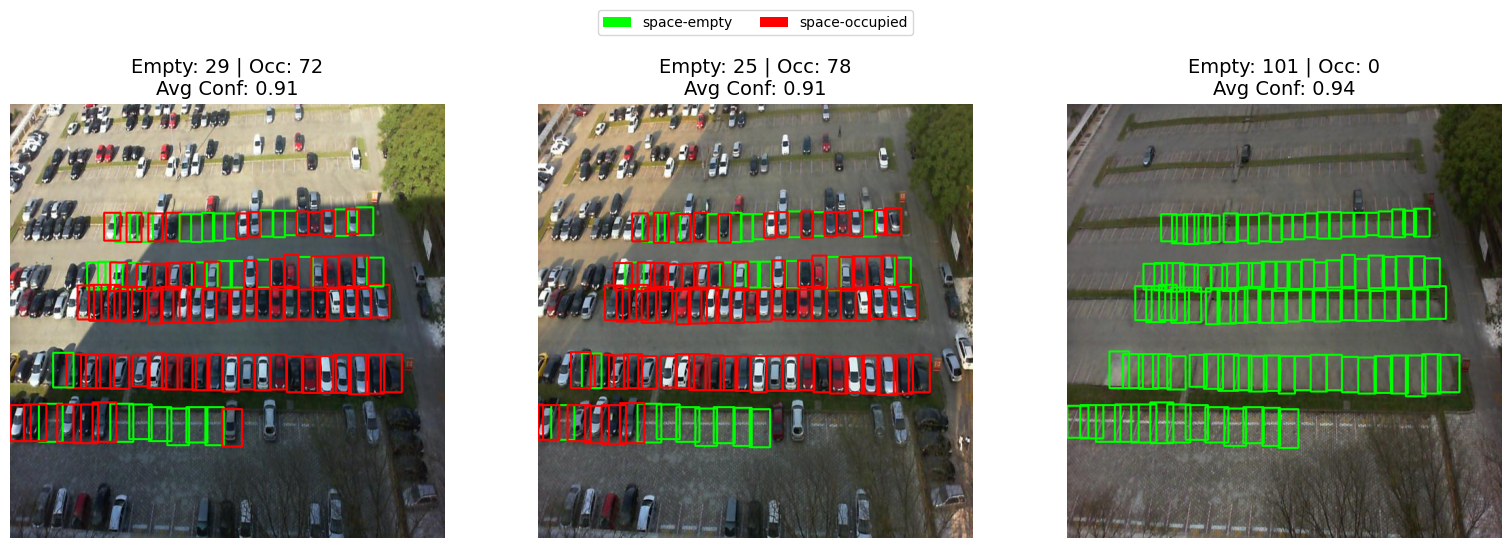

In [14]:
image_files = sorted([f for f in os.listdir(TEST_PATH) if f.endswith(('.png', '.jpg', '.jpeg'))])
test_yolo_and_show_results(best_model_rt, TEST_PATH, image_files, num_images=3)

## RT-DETR Detection Results

In [15]:
metrics_rt = best_model_rt.val(
    data='/kaggle/working/data.yaml',
    imgsz=480,
    split='test',
    save_json=True,
    device='cuda'
)

Ultralytics 8.3.235 🚀 Python-3.11.13 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
rt-detr-l summary: 302 layers, 31,987,850 parameters, 0 gradients, 103.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1748.1±405.5 MB/s, size: 73.3 KB)
val: Scanning /kaggle/working/custom_yolo_data/test/labels... 1242 images, 26 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1242/1242 1.2Kit/s 1.0s
val: New cache created: /kaggle/working/custom_yolo_data/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 78/78 1.4it/s 55.3s
                   all       1242      70684      0.989      0.994      0.991      0.901
           space-empty       1041      36584      0.982       0.99      0.989      0.907
        space-occupied        991      34100      0.995      0.998      0.994      0.895
Speed: 0.5ms preprocess, 36.7ms inference, 0.0ms loss, 0.4ms postprocess per image
Saving /kaggle/working/runs/detect/val/predictions.json.

In [16]:
TEST_IMAGES_DIR = "/kaggle/working/custom_yolo_data/test/images"
TEST_LABELS_DIR = "/kaggle/working/custom_yolo_data/test/labels"

iou_rt = compute_mean_iou_for_model(best_model_rt, TEST_IMAGES_DIR, TEST_LABELS_DIR, imgsz=480, conf=0.25)

In [17]:
mAP_50 = metrics_rt.box.map50
mAP_50_95 = metrics_rt.box.map
precision = metrics_rt.box.mp
recall = metrics_rt.box.mr
iou_overall = iou_rt['IoU_overall']
iou_space = iou_rt['IoU_space-empty']
iou_nospace = iou_rt['IoU_space-occupied']

print("Overall Test Dataset Metrics")

print(f"Test Dataset Accuracy Metrics")
print(f"mAP@0.5 (IoU >= 0.5): {mAP_50:.4f}")
print(f"IoU: {iou_overall:.4f}")
print(f"mAP@0.5:0.95 (Full COCO Metric): {mAP_50_95:.4f}")
print(f"Average Precision (P): {precision:.4f}")
print(f"Average Recall (R): {recall:.4f}")

print("\nPer-Class mAP05 Metrics")

class_ids = list(metrics_rt.names.keys())
class_names = [metrics_rt.names[i] for i in class_ids]
per_class_map50_95 = metrics_rt.box.maps

for cid, cname, m in zip(class_ids, class_names, per_class_map50_95):
    print(f"{cname} - mAP50-95: {m:.4f}")

print("\nPer-Class IoU Metrics")
per_class_iou = [iou_space, iou_nospace]
for cid, cname, m in zip(class_ids, class_names, per_class_iou):
    print(f"{cname} - IOU: {m:.4f}")

Overall Test Dataset Metrics
Test Dataset Accuracy Metrics
mAP@0.5 (IoU >= 0.5): 0.9913
IoU: 0.9265
mAP@0.5:0.95 (Full COCO Metric): 0.9009
Average Precision (P): 0.9888
Average Recall (R): 0.9940

Per-Class mAP05 Metrics
space-empty - mAP50-95: 0.9070
space-occupied - mAP50-95: 0.8948

Per-Class IoU Metrics
space-empty - IOU: 0.9281
space-occupied - IOU: 0.9249


In [18]:
benchmark_results_rt = best_model_rt.benchmark(imgsz=480,device='cuda', half=False, export=False)

Setup complete ✅ (4 CPUs, 31.4 GB RAM, 6576.8/8062.4 GB disk)

Benchmarks complete for /kaggle/working/runs/detect/train/weights/best.pt on coco8.yaml at imgsz=480 (453.37s)
Benchmarks legend:  - ✅ Success  - ❎ Export passed but validation failed  - ❌️ Export failed
+----------------------------------------------------------------------------------------------------------+
|      Format                  Status❔   Size (MB)   metrics/mAP50-95(B)   Inference time (ms/im)   FPS   |
+==========================================================================================================+
| 1    PyTorch                 ✅         63.1        0.0                   53.55                    18.67 |
| 2    TorchScript             ❎         123.0       -                     -                        -     |
| 3    ONNX                    ✅         125.2       0.0                   36.36                    27.5  |
| 4    OpenVINO                ❌         0.0         -                     -       

In [19]:
results_df_rt = pd.DataFrame(benchmark_results_rt)
results_df_rt.columns  = benchmark_results_rt.columns

In [20]:
pytorch_results_rt = results_df_rt.iloc[0]
inference_fps_rt = pytorch_results_rt['FPS']

gflops_rt = best_model_rt.model.info()[-1]
model_size_mb_rt = os.path.getsize(best_model_path) / (1024 * 1024)

print("\nModel Speed & Complexity Metrics")
print(f"Inference Speed (FPS, PyTorch): {inference_fps_rt}")
print(f"Model Size: {model_size_mb_rt:.2f} MB")
print(f"GFLOPs: {gflops_rt:.3f}")

rt-detr-l summary: 302 layers, 31,987,850 parameters, 0 gradients, 103.4 GFLOPs

Model Speed & Complexity Metrics
Inference Speed (FPS, PyTorch): 18.67
Model Size: 63.11 MB
GFLOPs: 103.437


# YOLOv11 and YOLOv12
This section utilizes the results and models from the previous project [🅿️YOLOv11 vs YOLOv12 |Comparative Analysis](https://www.kaggle.com/code/ninamaamary/yolov11-vs-yolov12-comparative-analysis/notebook)

## Load The Best Model YOLOv11

In [21]:
best_model_path = '/kaggle/input/pklot-yolo-rtdetr/pytorch/default/2/pklot_yolo_rtdetr/yolov11_best.pt'
best_model_11 = YOLO(best_model_path)

In [22]:
best_model_path = '/kaggle/input/pklot-yolo-rtdetr/pytorch/default/2/pklot_yolo_rtdetr/yolo12_best.pt'
best_model_12 = YOLO(best_model_path)

<p align="center">
    <h1 align=center style="font-size: 32px; font-family: Arial, sans-serif; margin-bottom: 12px;">
    <a href="https://www.kaggle.com/code/ninamaamary/yolov11-vs-yolov12-comparative-analysis/notebook"><b>Results from 🅿️YOLOv11 vs YOLOv12 |Comparative Analysis</b></a>
    </h1>
  <div style="display: flex; gap: 16px; margin: 18px 0;">
    <img src="https://ik.imagekit.io/xuwst6dbn/map.png" width=800 style="width: 50%; border-radius: 8px;">
    <img src="https://ik.imagekit.io/xuwst6dbn/iou.png" width=800 style="width: 50%; border-radius: 8px;">  
  </div>
</p>

# Fill Metrics values

In [23]:
# YOLOv11
mAP_50_11= 0.987
mAP_50_95_11= 0.822

mAP_50_empty_11= 0.983
mAP_50_occ_11= 0.99

mAP_50_95_empty_11= 0.827
mAP_50_95_occ_11= 0.813

iou_overall_11= 0.89
iou_space_11= 0.889
iou_nospace_11= 0.889

inference_fps_11 = 29.78
gflops_11 = best_model_11.model.info()[-1]
model_size_mb_11 = os.path.getsize(best_model_path) / (1024 * 1024)

# YOLOv12
mAP_50_12= 0.988
mAP_50_95_12= 0.830

mAP_50_empty_12= 0.986
mAP_50_occ_12= 0.991

mAP_50_95_empty_12= 0.835
mAP_50_95_occ_12= 0.835

iou_overall_12= 0.897
iou_space_12= 0.896
iou_nospace_12= 0.898

inference_fps_12 = 38.52
gflops_12 = best_model_12.model.info()[-1]
model_size_mb_12 = os.path.getsize(best_model_path) / (1024 * 1024)

YOLO11n summary: 181 layers, 2,590,230 parameters, 0 gradients, 6.4 GFLOPs
YOLOv12n summary: 272 layers, 2,568,438 parameters, 0 gradients, 6.5 GFLOPs


# Compare RT_DETR vs YOLOv11 vs YOLOv12 Results

In [24]:
def determine_winner(row):
    metric_name = str(row.name)

    v11 = row["YOLOv11-best"]
    v12 = row["YOLOv12-best"]
    vrt = row["RT-DETR-best"]

    values = {
        "YOLOv11-best": v11,
        "YOLOv12-best": v12,
        "RT-DETR-best": vrt,
    }

    # Drop NaNs so idxmax/min works correctly
    values = {k: v for k, v in values.items() if pd.notna(v)}
 
    # For FLOPs and Size → lower is better, otherwise higher is better
    if metric_name in ("FLOPs", "Size"):
        best_val = min(values.values())
    else:
        best_val = max(values.values())

    winners = [model for model, val in values.items() if val == best_val]
    return ", ".join(winners)

def draw_gt_image(image_path, labels_path):
    image = cv2.imread(image_path)
    if image is None:
        return None, [], 0, 0

    img_with_gt = image.copy()
    H, W = img_with_gt.shape[:2]

    gt_boxes = []
    empty_count = 0
    occupied_count = 0

    if os.path.exists(labels_path):
        with open(labels_path, "r") as f:
            for line in f:
                cls_id, xc, yc, w, h = map(float, line.split())
                cls_id = int(cls_id)

                # YOLO normalized xywh -> pixel xyxy
                x1 = int((xc - w/2) * W)
                y1 = int((yc - h/2) * H)
                x2 = int((xc + w/2) * W)
                y2 = int((yc + h/2) * H)

                gt_boxes.append((cls_id, x1, y1, x2, y2))

                # Count GT per class
                if cls_id == 0:      # space-empty
                    empty_count += 1
                elif cls_id == 1:    # space-occupied
                    occupied_count += 1

                color = CLASS_COLORS.get(cls_id, CLASS_COLORS["default"])["clr"]
                cv2.rectangle(img_with_gt, (x1, y1), (x2, y2), color, 2)

    return img_with_gt, gt_boxes, empty_count, occupied_count

def compute_iou(boxA, boxB):
    xA = max(boxA[0], boxB[0])
    yA = max(boxA[1], boxB[1])
    xB = min(boxA[2], boxB[2])
    yB = min(boxA[3], boxB[3])

    interW = max(0, xB - xA)
    interH = max(0, yB - yA)
    interArea = interW * interH

    if interArea == 0:
        return 0.0

    boxA_area = (boxA[2] - boxA[0]) * (boxA[3] - boxA[1])
    boxB_area = (boxB[2] - boxB[0]) * (boxB[3] - boxB[1])

    return interArea / float(boxA_area + boxB_area - interArea)

def compare_models_with_gt(model11, model12, model_rt, images_dir, labels_dir,
                           num_images=6, imgsz=480, conf=0.25):

    image_files = np.random.permutation([
        f for f in os.listdir(images_dir)
        if f.lower().endswith((".jpg", ".png", ".jpeg"))
    ])

    num_to_display = min(num_images, len(image_files))
    rows = num_to_display
    cols = 4   # GT | YOLO11 | YOLO12 | RT-DETR

    fig = plt.figure(figsize=(16, 4 * rows))

    for i in range(num_to_display):
        fname = image_files[i]
        img_path = os.path.join(images_dir, fname)
        label_path = os.path.join(labels_dir, fname.rsplit(".", 1)[0] + ".txt")

        # Ground truth
        gt_img, gt_boxes, gt_empty, gt_occ = draw_gt_image(img_path, label_path)

        ax1 = fig.add_subplot(rows, cols, i * cols + 1)
        ax1.imshow(cv2.cvtColor(gt_img, cv2.COLOR_BGR2RGB))
        ax1.set_title(f"GT\nEmpty:{gt_empty} Occ:{gt_occ}", fontsize=11, fontweight="bold")
        ax1.axis("off")

        # YOLOv11
        res = model11(img_path, imgsz=imgsz, conf=conf, verbose=False)[0]
        img11 = cv2.imread(img_path).copy()

        pred11 = []
        empty11 = occ11 = 0

        if res.boxes is not None:
            boxes = res.boxes.xyxy.cpu().numpy().astype(int)
            classes = res.boxes.cls.cpu().numpy().astype(int)

            for (x1, y1, x2, y2), cls_id in zip(boxes, classes):
                pred11.append((cls_id, x1, y1, x2, y2))
                if cls_id == 0: empty11 += 1
                if cls_id == 1: occ11 += 1
                color = CLASS_COLORS.get(cls_id, CLASS_COLORS["default"])["clr"]
                cv2.rectangle(img11, (x1, y1), (x2, y2), color, 2)

        ax2 = fig.add_subplot(rows, cols, i * cols + 2)
        ax2.imshow(cv2.cvtColor(img11, cv2.COLOR_BGR2RGB))
        ax2.set_title(f"YOLOv11\nEmpty:{empty11} Occ:{occ11}", fontsize=11)
        ax2.axis("off")

        # YOLOv12
        res = model12(img_path, imgsz=imgsz, conf=conf, verbose=False)[0]
        img12 = cv2.imread(img_path).copy()

        pred12 = []
        empty12 = occ12 = 0

        if res.boxes is not None:
            boxes = res.boxes.xyxy.cpu().numpy().astype(int)
            classes = res.boxes.cls.cpu().numpy().astype(int)

            for (x1, y1, x2, y2), cls_id in zip(boxes, classes):
                pred12.append((cls_id, x1, y1, x2, y2))
                if cls_id == 0: empty12 += 1
                if cls_id == 1: occ12 += 1
                color = CLASS_COLORS.get(cls_id, CLASS_COLORS["default"])["clr"]
                cv2.rectangle(img12, (x1, y1), (x2, y2), color, 2)

        ax3 = fig.add_subplot(rows, cols, i * cols + 3)
        ax3.imshow(cv2.cvtColor(img12, cv2.COLOR_BGR2RGB))
        ax3.set_title(f"YOLOv12\nEmpty:{empty12} Occ:{occ12}", fontsize=11)
        ax3.axis("off")

        # RT-DETR
        res = model_rt(img_path, imgsz=imgsz, conf=conf, verbose=False)[0]
        img_rt = cv2.imread(img_path).copy()

        pred_rt = []
        empty_rt = occ_rt = 0

        if res.boxes is not None:
            boxes = res.boxes.xyxy.cpu().numpy().astype(int)
            classes = res.boxes.cls.cpu().numpy().astype(int)

            for (x1, y1, x2, y2), cls_id in zip(boxes, classes):
                pred_rt.append((cls_id, x1, y1, x2, y2))
                if cls_id == 0: empty_rt += 1
                if cls_id == 1: occ_rt += 1
                color = CLASS_COLORS.get(cls_id, CLASS_COLORS["default"])["clr"]
                cv2.rectangle(img_rt, (x1, y1), (x2, y2), color, 2)

        ax4 = fig.add_subplot(rows, cols, i * cols + 4)
        ax4.imshow(cv2.cvtColor(img_rt, cv2.COLOR_BGR2RGB))
        ax4.set_title(f"RT-DETR\nEmpty:{empty_rt} Occ:{occ_rt}", fontsize=11)
        ax4.axis("off")

    # Legend
    legend_handles = [
        Patch(
            facecolor=(v['clr'][2]/255., v['clr'][1]/255., v['clr'][0]/255.),
            label=v['name']
        )
        for k, v in CLASS_COLORS.items() if k != 'default'
    ]
    fig.legend(handles=legend_handles, ncol=len(legend_handles),
               loc="upper center", bbox_to_anchor=(0.5, 1.03))
    plt.tight_layout()
    plt.show()

In [25]:
# YOLOv11 metrics dict
metrics_11_dict = {
    "mAP50_overall":      mAP_50_11,
    "mAP50-90_overall":   mAP_50_95_11,

    "mAP50_space-empty":  mAP_50_empty_11,
    "mAP50_space-occupied": mAP_50_occ_11,

    "IoU_overall":        iou_overall_11,
    "IoU_space-empty":    iou_space_11,
    "IoU_space-occupied": iou_nospace_11,

    "FPS":                inference_fps_11,
    "FLOPs":              gflops_11,
    "Size_MB":            model_size_mb_11,
}

# YOLOv12 metrics dict
metrics_12_dict = {
    "mAP50_overall":      mAP_50_12,
    "mAP50-90_overall":   mAP_50_95_12,

    "mAP50_space-empty":  mAP_50_empty_12,
    "mAP50_space-occupied": mAP_50_occ_12,

    "IoU_overall":        iou_overall_12,
    "IoU_space-empty":    iou_space_12,
    "IoU_space-occupied": iou_nospace_12,

    "FPS":                inference_fps_12,
    "FLOPs":              gflops_12,
    "Size_MB":            model_size_mb_12,
}

metrics_rt_dict = {
    "mAP50_overall":      metrics_rt.box.map50,
    "mAP50-90_overall":   metrics_rt.box.map,

    "mAP50_space-empty":  metrics_rt.box.maps[0],
    "mAP50_space-occupied": metrics_rt.box.maps[1],

    "IoU_overall":        iou_rt['IoU_overall'],
    "IoU_space-empty":    iou_rt['IoU_space-empty'],
    "IoU_space-occupied": iou_rt['IoU_space-occupied'],

    "FPS":                float(inference_fps_rt),
    "FLOPs":              gflops_rt,
    "Size_MB":            model_size_mb_rt,
}


df_11 = pd.DataFrame.from_dict(metrics_11_dict, orient="index", columns=["YOLOv11-best"])
df_12 = pd.DataFrame.from_dict(metrics_12_dict, orient="index", columns=["YOLOv12-best"])
df_rt = pd.DataFrame.from_dict(metrics_rt_dict, orient="index", columns=["RT-DETR-best"])

metrics_compare_df = pd.concat([df_11, df_12, df_rt], axis=1)
metrics_compare_df["Winner"] = metrics_compare_df.apply(determine_winner, axis=1)

,YOLOv11-best,YOLOv12-best,RT-DETR-best,Winner
mAP50_overall,0.987000,0.988000,0.991288,RT-DETR-best
mAP50-90_overall,0.822000,0.830000,0.900907,RT-DETR-best
mAP50_space-empty,0.983000,0.986000,0.906991,YOLOv12-best
mAP50_space-occupied,0.990000,0.991000,0.894822,YOLOv12-best
IoU_overall,0.890000,0.897000,0.926542,RT-DETR-best
IoU_space-empty,0.889000,0.896000,0.928118,RT-DETR-best
IoU_space-occupied,0.889000,0.898000,0.924859,RT-DETR-best
FPS,29.780000,38.520000,18.670000,YOLOv12-best
FLOPs,6.441677,6.480896,103.437414,YOLOv11-best
Size_MB,5.234454,5.234454,63.113272,RT-DETR-best


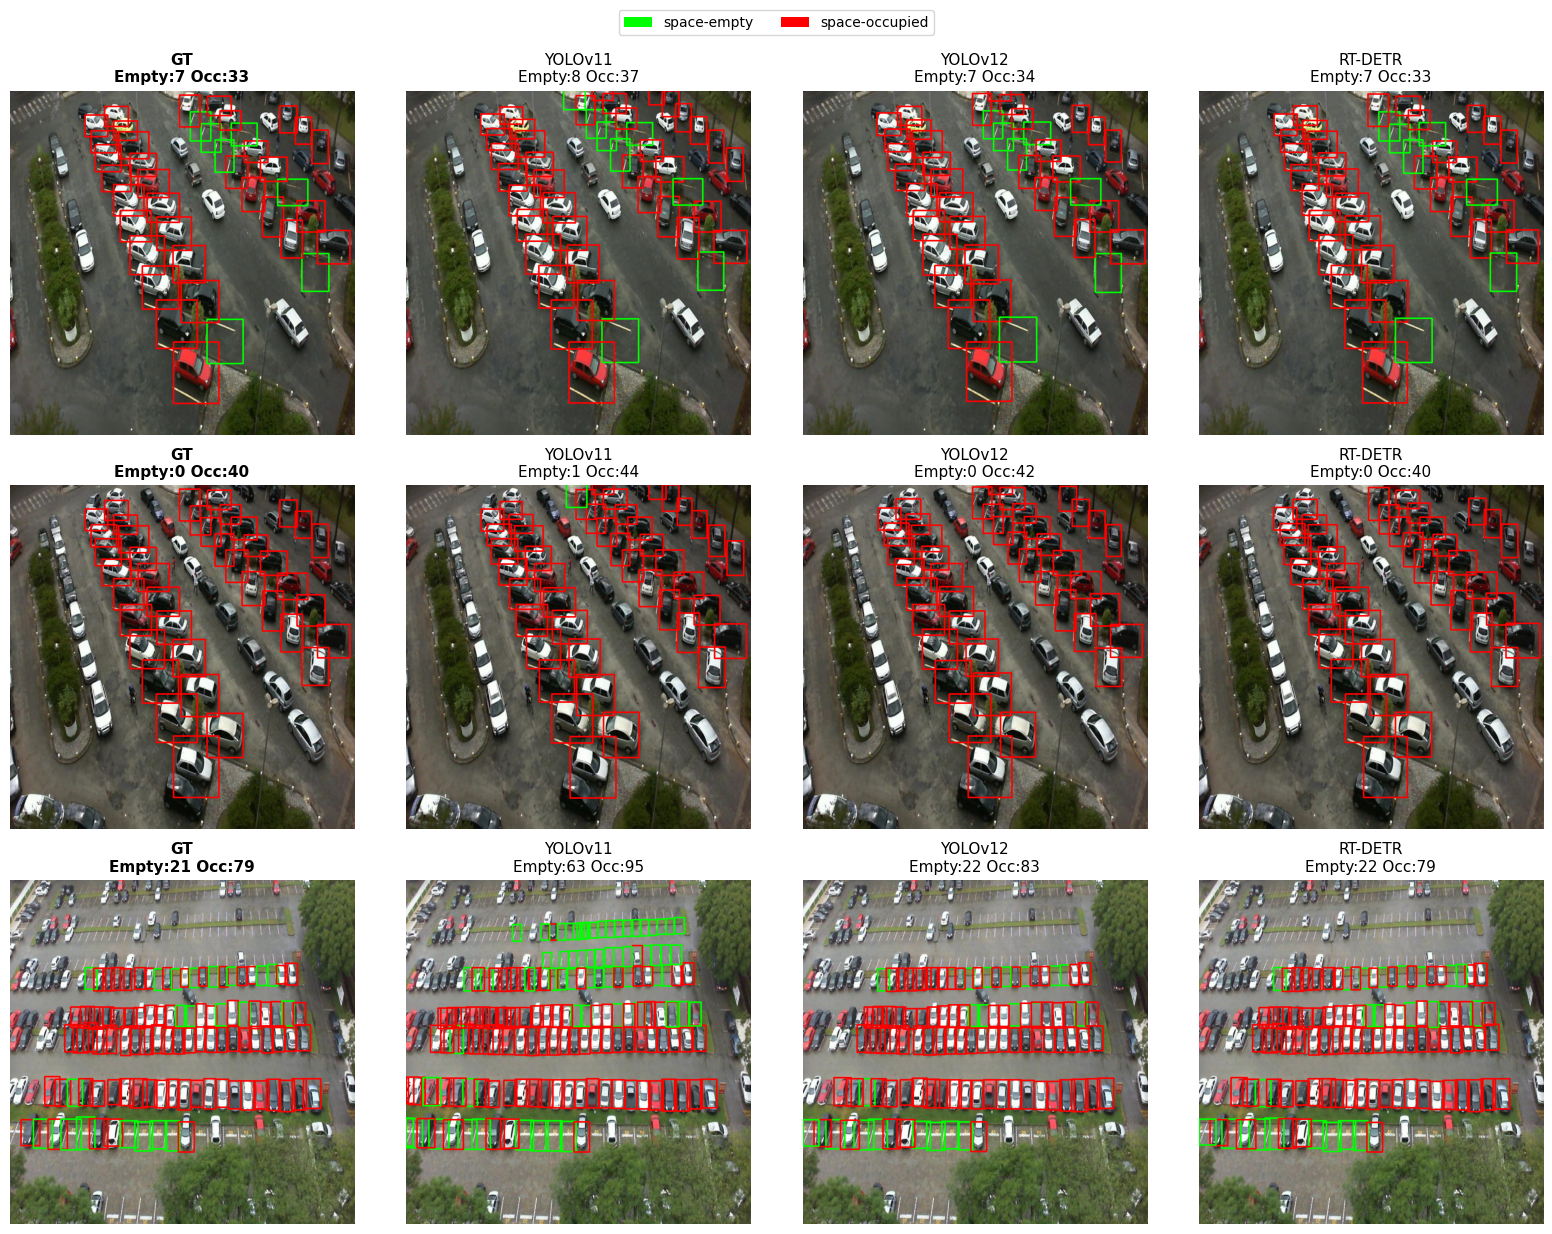

In [26]:
TEST_IMAGES_DIR = "/kaggle/working/custom_yolo_data/test/images"
TEST_LABELS_DIR = "/kaggle/working/custom_yolo_data/test/labels"

display(metrics_compare_df)

compare_models_with_gt(
    model11=best_model_11,
    model12=best_model_12,
    model_rt=best_model_rt,
    images_dir=TEST_IMAGES_DIR,
    labels_dir=TEST_LABELS_DIR,
    num_images=3
)

# Graph Results

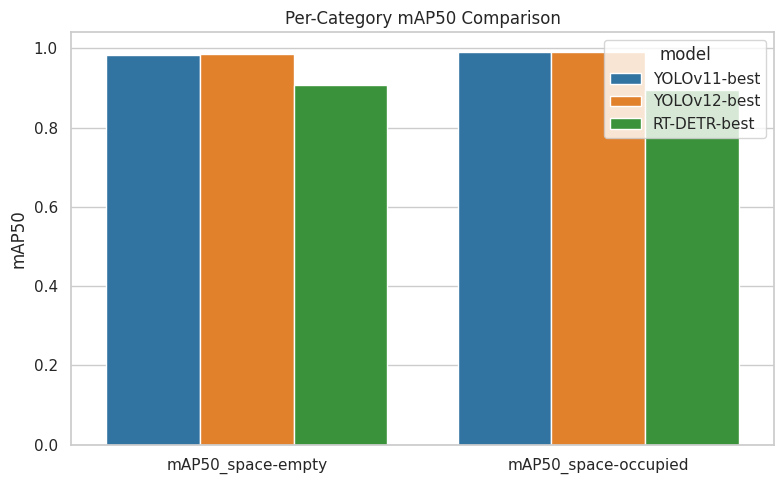

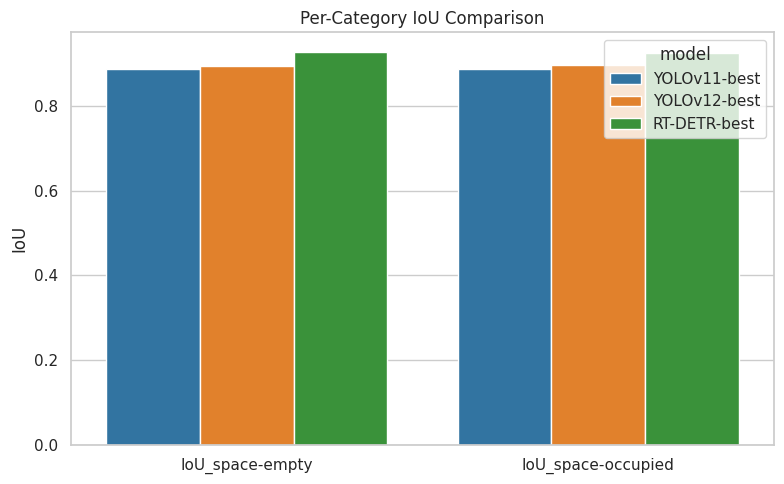

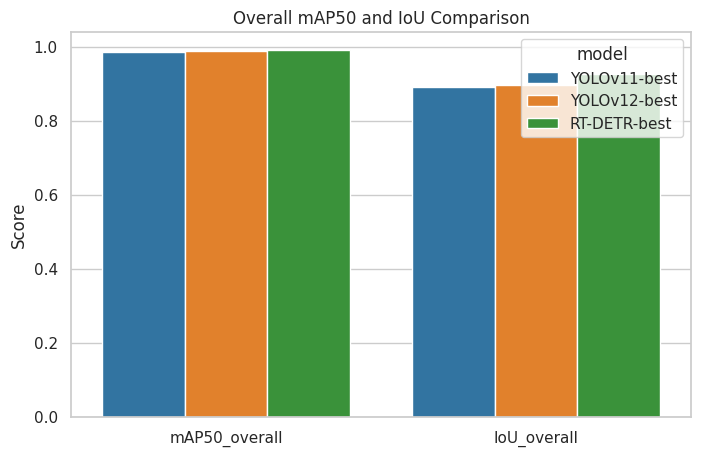

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

sns.set(style="whitegrid")


# Melt metrics_compare_df to long (tidy) format
metrics_compare_df_clean = metrics_compare_df.drop(columns=["Winner"])
df_long = (
    metrics_compare_df_clean
    .reset_index()
    .rename(columns={"index": "metric"})
    .melt(id_vars="metric", var_name="model", value_name="score")
)
df_long["score"] = pd.to_numeric(df_long["score"], errors="coerce")

# Per-category mAP50  (no 'overall')
df_map = df_long[df_long["metric"].str.contains("mAP50_")]
df_map = df_map[~df_map["metric"].str.contains("overall")]

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=df_map, x="metric", y="score", hue="model", palette="tab10")
ax.set_title("Per-Category mAP50 Comparison")
ax.set_ylabel("mAP50")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

# Per-category IoU (no 'overall')
df_iou = df_long[df_long["metric"].str.contains("IoU_")]
df_iou = df_iou[~df_iou["metric"].str.contains("overall")]

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=df_iou, x="metric", y="score", hue="model", palette="tab10")
ax.set_title("Per-Category IoU Comparison")
ax.set_ylabel("IoU")
ax.set_xlabel("")
plt.tight_layout()
plt.show()


# Overall mAP50 + IoU
df_overall = df_long[df_long["metric"].isin(["mAP50_overall", "IoU_overall"])]

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=df_overall, x="metric", y="score", hue="model",palette="tab10")
ax.set_title("Overall mAP50 and IoU Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("")
plt.show()

# Out-of-Domain Images

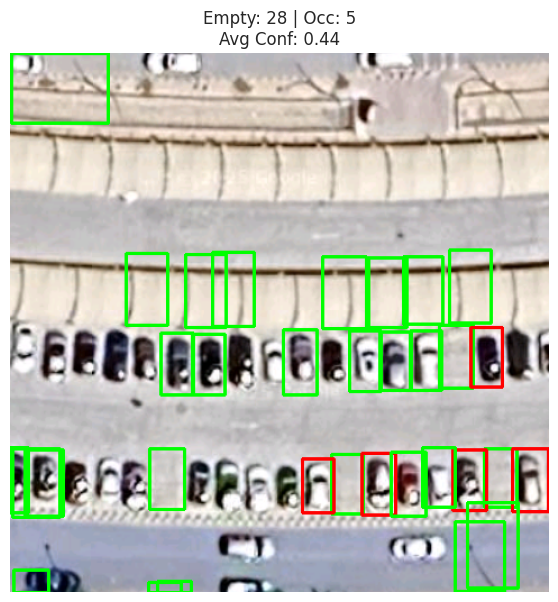

In [28]:
single_image_path = '/kaggle/input/pklot-yolo-rtdetr/pytorch/default/2/street.png'
results = best_model_rt(single_image_path, imgsz=480, conf=0.25, verbose=False)
avg_conf, img_with_boxes, empty_cnt, occ_cnt = draw_yolo_on_ax(results, single_image_path)

plt.figure(figsize=(7, 7))
plt.imshow(cv2.cvtColor(img_with_boxes, cv2.COLOR_BGR2RGB))
plt.title(f"Empty: {empty_cnt} | Occ: {occ_cnt}\nAvg Conf: {avg_conf:.2f}")
plt.axis("off")
plt.show()

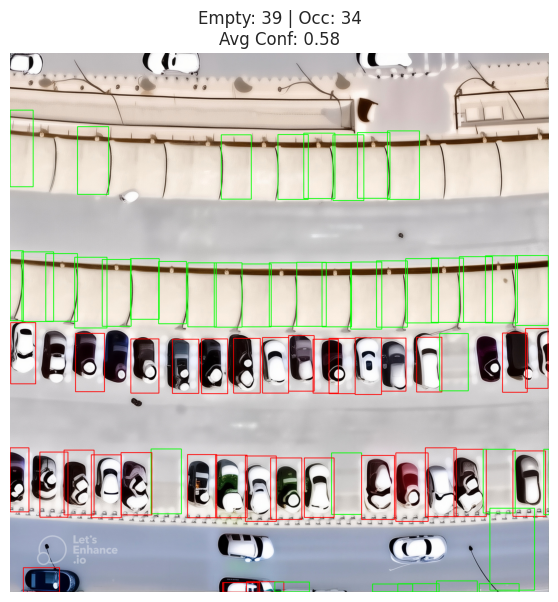

In [29]:
single_image_path = '/kaggle/input/pklot-yolo-rtdetr/pytorch/default/2/street2.jpg'
results = best_model_rt(single_image_path, imgsz=480, conf=0.25, verbose=False)
avg_conf, img_with_boxes, empty_cnt, occ_cnt = draw_yolo_on_ax(results, single_image_path)

plt.figure(figsize=(7, 7))
plt.imshow(cv2.cvtColor(img_with_boxes, cv2.COLOR_BGR2RGB))
plt.title(f"Empty: {empty_cnt} | Occ: {occ_cnt}\nAvg Conf: {avg_conf:.2f}")
plt.axis("off")
plt.show()

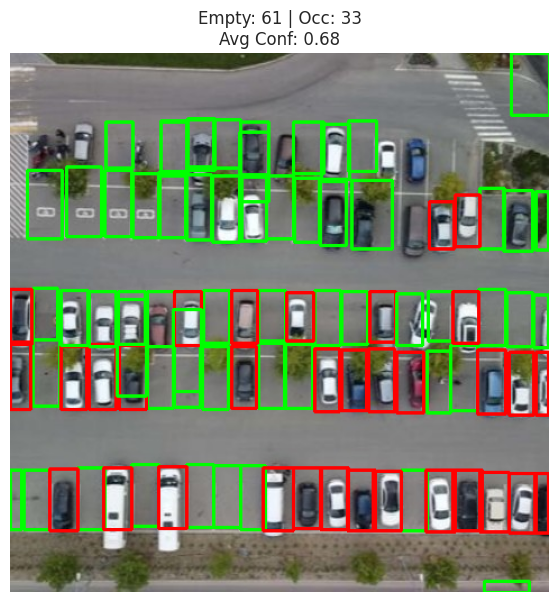

In [30]:
single_image_path = '/kaggle/input/pklot-yolo-rtdetr/pytorch/default/2/street3.jpg'
results = best_model_rt(single_image_path, imgsz=480, conf=0.25, verbose=False)
avg_conf, img_with_boxes, empty_cnt, occ_cnt = draw_yolo_on_ax(results, single_image_path)

plt.figure(figsize=(7, 7))
plt.imshow(cv2.cvtColor(img_with_boxes, cv2.COLOR_BGR2RGB))
plt.title(f"Empty: {empty_cnt} | Occ: {occ_cnt}\nAvg Conf: {avg_conf:.2f}")
plt.axis("off")
plt.show()